# Atelier 1 - Regression NYSE avec PyTorch

## Objectif et perimetre

Dans ce notebook, je réalise la **partie 1 (régression)** de l'atelier de Deep Learning. Pour une action donnée, je cherche à prédire son prix de clôture ajusté au prochain jour de cotation à partir des informations disponibles au jour courant.

- **Table utilisée :** `prices-split-adjusted.csv`
- **Entrées :** `open`, `high`, `low`, `close`, `volume`
- **Cible :** `target_next_close`
- **Modèle principal :** perceptron multicouche (MLP) PyTorch
- **Évaluation :** MAE, RMSE, R² et pourcentage de prédictions à ±5 % de la cible

Je ne traite pas la classification multiclasse (partie 2) dans ce rendu.

In [1]:
from pathlib import Path
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

NYSE_DIR = PROJECT_ROOT / "data" / "raw" / "nyse"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (10, 5), "axes.titleweight": "bold"})

print("Projet       :", PROJECT_ROOT)
print("Données NYSE :", NYSE_DIR)
print("Device       :", "cuda" if torch.cuda.is_available() else "cpu")

Projet       : C:\Users\berqi\Desktop\DL-Lab-1
Données NYSE : C:\Users\berqi\Desktop\DL-Lab-1\data\raw\nyse
Device       : cuda


## 1. Inventorier les fichiers NYSE

Un dataset peut contenir plusieurs tables ayant des rôles différents. Avant de choisir les entrées et la cible, il faut donc connaître les fichiers disponibles.

In [2]:
nyse_files = pd.DataFrame({
    "file": [path.name for path in sorted(NYSE_DIR.glob("*.csv"))],
    "size_mb": [path.stat().st_size / (1024 ** 2) for path in sorted(NYSE_DIR.glob("*.csv"))],
})

nyse_files.round({"size_mb": 2})

,file,size_mb
0,fundamentals.csv,1.35
1,prices-split-adjusted.csv,50.26
2,prices.csv,49.27
3,securities.csv,0.06


### Rôle des fichiers

- `prices.csv` : prix journaliers tels qu'enregistrés ;
- `prices-split-adjusted.csv` : prix corrigés des divisions d'actions (*stock splits*) ;
- `securities.csv` : informations descriptives sur les entreprises ;
- `fundamentals.csv` : données comptables et financières.

Pour commencer la régression sur les prix, nous utiliserons `prices-split-adjusted.csv`. Ce choix évite que les divisions d'actions apparaissent comme de brusques chutes économiques du prix.

## 2. Charger la table des prix

`parse_dates=["date"]` demande à pandas de convertir la colonne `date` en véritable type temporel au moment du chargement.

In [3]:
PRICES_PATH = NYSE_DIR / "prices-split-adjusted.csv"

prices = pd.read_csv(PRICES_PATH, parse_dates=["date"])
prices.head()

,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0


## Checks — réponds avant de poursuivre

Après avoir exécuté la cellule de chargement, observe les cinq premières lignes puis réponds :

1. Que représente une ligne de `prices` ?
2. Combien de colonnes vois-tu et quels sont leurs noms ?
3. Quelle colonne identifie l'entreprise ?
4. Quelle différence imagines-tu entre `open`, `close`, `low` et `high` ?
5. Que représente probablement `volume` ?

Nous inspecterons ensuite le `shape`, les types, les valeurs manquantes, la période couverte et le nombre d'entreprises avant toute visualisation ou modélisation.

## 3. Structure et qualité des données

Je vérifie ici les dimensions, les types, la période couverte, les valeurs manquantes, les doublons et la cohérence des prix OHLC. Je conserve les 21 volumes nuls : ils sont rares et ne violent pas les contraintes de prix.

In [4]:
print("Shape :", prices.shape)
print()
print("Types :")
print(prices.dtypes)
print()
print("Valeurs manquantes :")
print(prices.isna().sum())

Shape : (851264, 7)

Types :
date      datetime64[us]
symbol               str
open             float64
close            float64
low              float64
high             float64
volume           float64
dtype: object

Valeurs manquantes :
date      0
symbol    0
open      0
close     0
low       0
high      0
volume    0
dtype: int64


In [5]:
print("Première date :", prices["date"].min())
print("Dernière date :", prices["date"].max())
print("Nombre d'actions :", prices["symbol"].nunique())
print(
    "Doublons date-action :",
    prices.duplicated(subset=["date", "symbol"]).sum()
)

Première date : 2010-01-04 00:00:00
Dernière date : 2016-12-30 00:00:00
Nombre d'actions : 501


Doublons date-action : 0


In [6]:
symbol_coverage = (
    prices
    .groupby("symbol")
    .agg(
        n_observations=("date", "size"),
        first_date=("date", "min"),
        last_date=("date", "max"),
    )
    .sort_values("n_observations")
)

display(symbol_coverage.head())
display(symbol_coverage.tail())

,n_observations,first_date,last_date
symbol,,,
FTV,126,2016-07-05,2016-12-30
WLTW,251,2016-01-05,2016-12-30
CSRA,284,2015-11-16,2016-12-30
HPE,304,2015-10-19,2016-12-30
KHC,378,2015-07-06,2016-12-30


,n_observations,first_date,last_date
symbol,,,
AET,1762,2010-01-04,2016-12-30
ZBH,1762,2010-01-04,2016-12-30
ZION,1762,2010-01-04,2016-12-30
AAL,1762,2010-01-04,2016-12-30
A,1762,2010-01-04,2016-12-30


In [7]:
prices[
    ["open", "close", "low", "high", "volume"]
].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
open,851264.0,64.99,75.20,1.66,31.27,48.46,75.12,1.584440e+03
close,851264.0,65.01,75.20,1.59,31.29,48.48,75.14,1.578130e+03
low,851264.0,64.34,74.46,1.50,30.94,47.97,74.40,1.549940e+03
high,851264.0,65.64,75.91,1.81,31.62,48.96,75.85,1.600930e+03
volume,851264.0,5415112.64,12494681.43,0.00,1221500.00,2476250.00,5222500.00,8.596434e+08


In [8]:
quality_checks = pd.Series({
    "volume_négatif": (prices["volume"] < 0).sum(),
    "volume_nul": (prices["volume"] == 0).sum(),
    "low_supérieur_open": (prices["low"] > prices["open"]).sum(),
    "low_supérieur_close": (prices["low"] > prices["close"]).sum(),
    "high_inférieur_open": (prices["high"] < prices["open"]).sum(),
    "high_inférieur_close": (prices["high"] < prices["close"]).sum(),
    "low_supérieur_high": (prices["low"] > prices["high"]).sum(),
})

quality_checks

volume_négatif           0
volume_nul              21
low_supérieur_open       0
low_supérieur_close      0
high_inférieur_open      0
high_inférieur_close     0
low_supérieur_high       0
dtype: int64

In [9]:
zero_volume = prices.loc[
    prices["volume"] == 0,
    ["date", "symbol", "open", "close", "low", "high", "volume"]
]

print("Nombre de lignes :", len(zero_volume))
display(zero_volume.head(10))

print("Nombre de volumes nuls par action :")
display(
    zero_volume
    .groupby("symbol")
    .size()
    .sort_values(ascending=False)
)

Nombre de lignes : 21


,date,symbol,open,close,low,high,volume
1270,2010-01-06,CHTR,35.000000,35.000000,35.000000,35.000000,0.0
13906,2010-02-16,CHTR,29.740000,29.740000,29.740000,29.740000,0.0
14374,2010-02-17,CHTR,29.740000,29.740000,29.740000,29.740000,0.0
15310,2010-02-19,CHTR,29.700001,29.700001,29.700001,29.700001,0.0
16246,2010-02-23,CHTR,29.700001,29.700001,29.700001,29.700001,0.0
16714,2010-02-24,CHTR,29.700001,29.700001,29.700001,29.700001,0.0
30754,2010-04-08,CHTR,34.549999,34.549999,34.549999,34.549999,0.0
32158,2010-04-13,CHTR,35.000000,35.000000,35.000000,35.000000,0.0
34498,2010-04-20,CHTR,36.009998,36.009998,36.009998,36.009998,0.0
42465,2010-05-13,CHTR,38.000000,38.000000,38.000000,38.000000,0.0


Nombre de volumes nuls par action :


symbol
CHTR    18
CB       1
SNI      1
VRTX     1
dtype: int64

## 4. Construction de la cible

Je crée la cible séparément pour chaque symbole avec `groupby(...).shift(-1)`. La dernière observation de chaque action n'a donc pas de cible et je la retire. Cette opération évite d'associer le cours d'une action à celui d'une autre.

In [10]:
prices = prices.sort_values(["symbol", "date"]).copy()

prices["target_next_close"] = (
    prices
    .groupby("symbol")["close"]
    .shift(-1)
)

prices[
    ["date", "symbol", "close", "target_next_close"]
].head(8)

,date,symbol,close,target_next_close
251,2010-01-04,A,22.389128,22.145923
718,2010-01-05,A,22.145923,22.067240
1186,2010-01-06,A,22.067240,22.038626
1654,2010-01-07,A,22.038626,22.031474
2122,2010-01-08,A,22.031474,22.045780
2590,2010-01-11,A,22.045780,21.781117
3058,2010-01-12,A,21.781117,21.952789
3526,2010-01-13,A,21.952789,22.281832


In [11]:
model_data = (
    prices
    .dropna(subset=["target_next_close"])
    .reset_index(drop=True)
)

print("Shape initial :", prices.shape)
print("Shape modèle  :", model_data.shape)
print(
    "Cibles manquantes :",
    model_data["target_next_close"].isna().sum()
)

Shape initial : (851264, 8)
Shape modèle  : (850763, 8)
Cibles manquantes : 0


## 5. Analyse exploratoire

Je me concentre sur AAPL afin de rendre la dynamique temporelle lisible sans superposer les 501 actions. La proximité du nuage de points avec la diagonale montre que le cours du lendemain est souvent proche du cours courant, ce qui motive mon choix d'une baseline de persistance.

Nombre d'observations : 1761
Première date : 2010-01-04 00:00:00
Dernière date : 2016-12-29 00:00:00


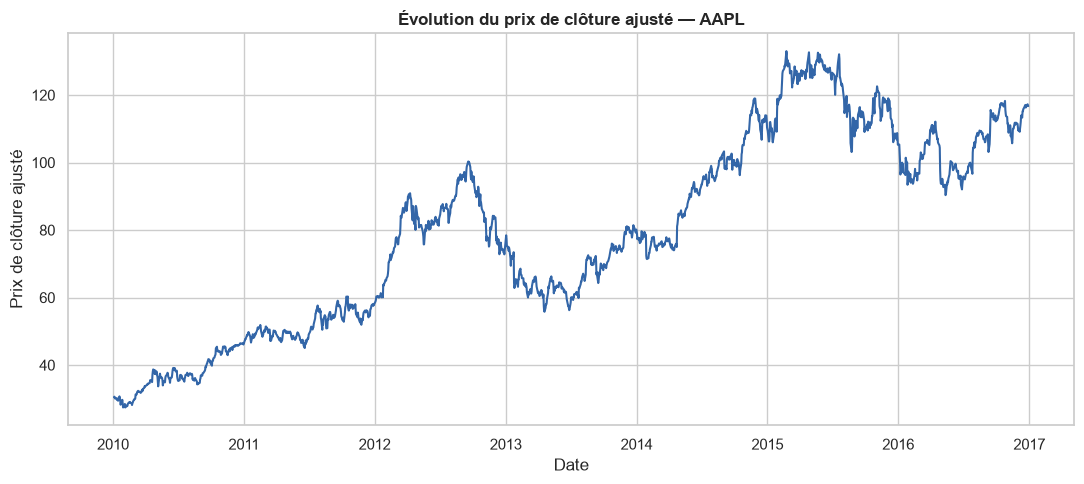

In [12]:
example_symbol = "AAPL"

example_prices = (
    model_data
    .loc[model_data["symbol"] == example_symbol]
    .sort_values("date")
)

print("Nombre d'observations :", len(example_prices))
print("Première date :", example_prices["date"].min())
print("Dernière date :", example_prices["date"].max())

fig, ax = plt.subplots(figsize=(11, 5))

sns.lineplot(
    data=example_prices,
    x="date",
    y="close",
    color="#3366A8",
    linewidth=1.5,
    ax=ax,
)

ax.set(
    title="Évolution du prix de clôture ajusté — AAPL",
    xlabel="Date",
    ylabel="Prix de clôture ajusté",
)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "01_aapl_close_over_time.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

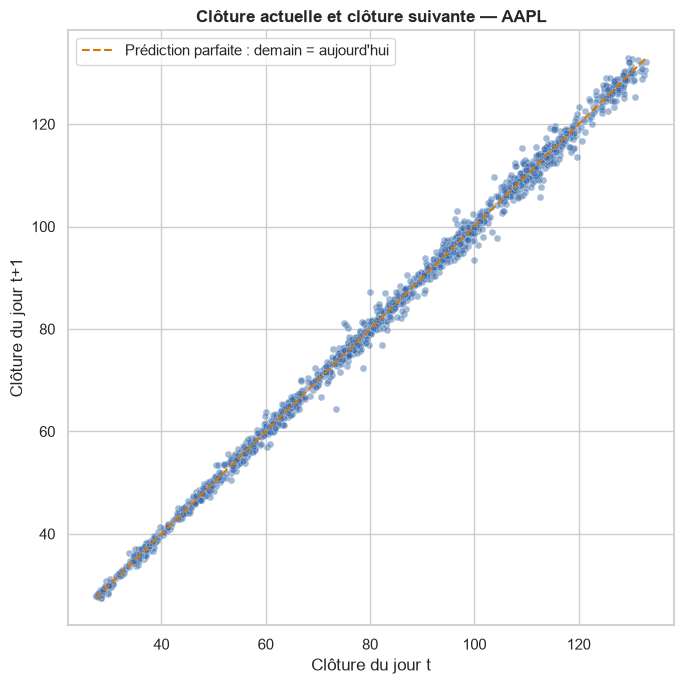

In [13]:
fig, ax = plt.subplots(figsize=(7, 7))

sns.scatterplot(
    data=example_prices,
    x="close",
    y="target_next_close",
    alpha=0.45,
    s=25,
    color="#3366A8",
    ax=ax,
)

min_price = min(
    example_prices["close"].min(),
    example_prices["target_next_close"].min(),
)
max_price = max(
    example_prices["close"].max(),
    example_prices["target_next_close"].max(),
)

ax.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--",
    color="#D97706",
    label="Prédiction parfaite : demain = aujourd'hui",
)

ax.set(
    title="Clôture actuelle et clôture suivante — AAPL",
    xlabel="Clôture du jour t",
    ylabel="Clôture du jour t+1",
)

ax.legend()
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "01_aapl_current_vs_next_close.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

In [14]:
baseline_errors = (
    example_prices["target_next_close"]
    - example_prices["close"]
)

baseline_mae = baseline_errors.abs().mean()
baseline_rmse = np.sqrt((baseline_errors ** 2).mean())

print("MAE baseline  :", round(baseline_mae, 4))
print("RMSE baseline :", round(baseline_rmse, 4))

MAE baseline  : 0.9278
RMSE baseline : 1.3393


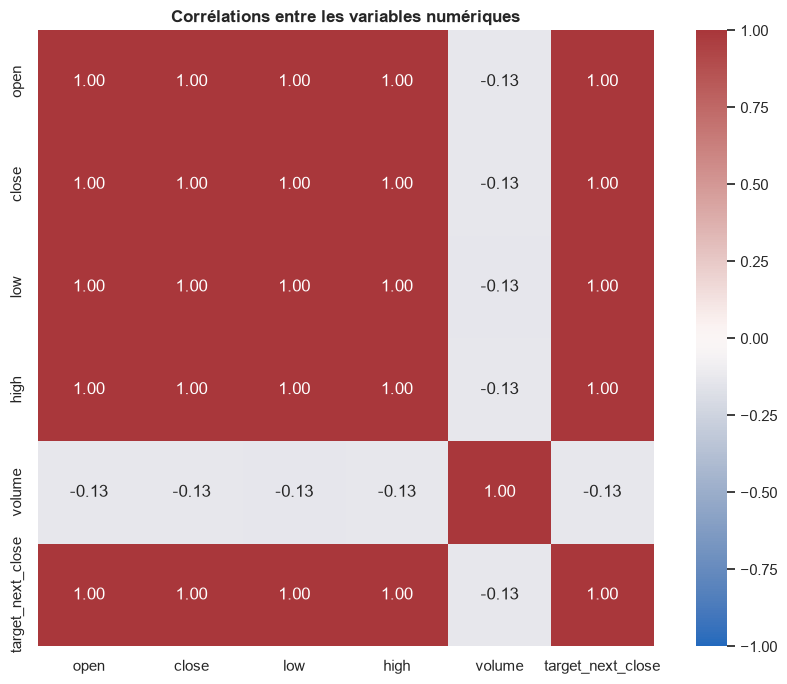

In [15]:
correlation_columns = [
    "open",
    "close",
    "low",
    "high",
    "volume",
    "target_next_close",
]

correlations = model_data[correlation_columns].corr()

fig, ax = plt.subplots(figsize=(9, 7))

sns.heatmap(
    correlations,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    vmin=-1,
    vmax=1,
    square=True,
    ax=ax,
)

ax.set_title("Corrélations entre les variables numériques")
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "01_numeric_correlations.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

## 6. Variables et découpage chronologique

J'utilise un découpage chronologique : entraînement avant 2015, validation en 2015 et test en 2016. Je reconstruis la cible dans chaque période afin qu'aucune observation d'une période suivante ne serve de cible à la période précédente.

In [16]:
FEATURE_COLUMNS = [
    "open",
    "high",
    "low",
    "close",
    "volume",
]

TARGET_COLUMN = "target_next_close"

X = model_data[FEATURE_COLUMNS]
y = model_data[TARGET_COLUMN]

print("Shape de X :", X.shape)
print("Shape de y :", y.shape)

Shape de X : (850763, 5)
Shape de y : (850763,)


In [17]:
def prepare_period(period_data):
    period_data = (
        period_data
        .sort_values(["symbol", "date"])
        .copy()
    )

    period_data["target_next_close"] = (
        period_data
        .groupby("symbol")["close"]
        .shift(-1)
    )

    return (
        period_data
        .dropna(subset=["target_next_close"])
        .reset_index(drop=True)
    )


train_data = prepare_period(
    prices.loc[prices["date"] < "2015-01-01"]
)

validation_data = prepare_period(
    prices.loc[
        (prices["date"] >= "2015-01-01")
        & (prices["date"] < "2016-01-01")
    ]
)

test_data = prepare_period(
    prices.loc[prices["date"] >= "2016-01-01"]
)


for name, dataset in [
    ("Train", train_data),
    ("Validation", validation_data),
    ("Test", test_data),
]:
    print(
        name,
        "| shape :", dataset.shape,
        "| période :", dataset["date"].min().date(),
        "→", dataset["date"].max().date(),
    )

Train | shape : (599692, 8) | période : 2010-01-04 → 2014-12-30
Validation | shape : (124458, 8) | période : 2015-01-02 → 2015-12-30
Test | shape : (125624, 8) | période : 2016-01-04 → 2016-12-29


In [18]:
test_baseline_predictions = test_data["close"]
test_targets = test_data["target_next_close"]

test_baseline_errors = (
    test_targets - test_baseline_predictions
)

test_baseline_mae = test_baseline_errors.abs().mean()
test_baseline_rmse = np.sqrt(
    (test_baseline_errors ** 2).mean()
)

print("Baseline test — MAE  :", round(test_baseline_mae, 4))
print("Baseline test — RMSE :", round(test_baseline_rmse, 4))

Baseline test — MAE  : 0.9484
Baseline test — RMSE : 2.1429


## 7. Standardisation sans fuite de données

J'ajuste les deux standardiseurs uniquement sur l'ensemble d'entraînement, puis je les applique à la validation et au test. J'empêche ainsi l'information future d'influencer le prétraitement.

In [19]:
from sklearn.preprocessing import StandardScaler

feature_scaler = StandardScaler()
target_scaler = StandardScaler()

X_train = feature_scaler.fit_transform(
    train_data[FEATURE_COLUMNS]
).astype(np.float32)

X_validation = feature_scaler.transform(
    validation_data[FEATURE_COLUMNS]
).astype(np.float32)

X_test = feature_scaler.transform(
    test_data[FEATURE_COLUMNS]
).astype(np.float32)


y_train = target_scaler.fit_transform(
    train_data[[TARGET_COLUMN]]
).astype(np.float32)

y_validation = target_scaler.transform(
    validation_data[[TARGET_COLUMN]]
).astype(np.float32)

y_test = target_scaler.transform(
    test_data[[TARGET_COLUMN]]
).astype(np.float32)


print("X_train :", X_train.shape)
print("y_train :", y_train.shape)
print("Moyennes X_train :", X_train.mean(axis=0).round(3))
print("Écarts-types X_train :", X_train.std(axis=0).round(3))

X_train : (599692, 5)
y_train : (599692, 1)
Moyennes X_train : [ 0. -0.  0. -0. -0.]
Écarts-types X_train : [1. 1. 1. 1. 1.]


In [20]:
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

np.savez(
    PROCESSED_DIR / "nyse_regression_arrays.npz",
    X_train=X_train,
    X_validation=X_validation,
    X_test=X_test,
    y_train=y_train,
    y_validation=y_validation,
    y_test=y_test,
)

print("Tableaux sauvegardés.")

Tableaux sauvegardés.


## 8. Tensors et mini-batches

Je convertis les tableaux NumPy en tensors `float32`. Je mélange seulement l'entraînement dans le `DataLoader` et je regroupe les exemples en mini-batches pour calculer une mise à jour des poids par batch.

In [21]:
from torch.utils.data import DataLoader, TensorDataset

BATCH_SIZE = 1024

train_dataset = TensorDataset(
    torch.from_numpy(X_train),
    torch.from_numpy(y_train),
)

validation_dataset = TensorDataset(
    torch.from_numpy(X_validation),
    torch.from_numpy(y_validation),
)

test_dataset = TensorDataset(
    torch.from_numpy(X_test),
    torch.from_numpy(y_test),
)

use_pin_memory = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=use_pin_memory,
    generator=torch.Generator().manual_seed(SEED),
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=use_pin_memory,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=use_pin_memory,
)

X_batch, y_batch = next(iter(train_loader))

print("Nombre de batches train :", len(train_loader))
print("Shape X_batch :", X_batch.shape)
print("Shape y_batch :", y_batch.shape)
print("Type X_batch :", X_batch.dtype)
print("Device actuel :", X_batch.device)

Nombre de batches train : 586
Shape X_batch : torch.Size([1024, 5])
Shape y_batch : torch.Size([1024, 1])
Type X_batch : torch.float32
Device actuel : cpu


## 9. MLP initial

J'ai choisi l'architecture `5 -> 64 -> 32 -> 1` : elle transforme les cinq variables d'entrée en deux représentations cachées, puis produit une seule valeur continue. Je sélectionne le meilleur état avec la loss de validation.

In [22]:
import torch.nn as nn

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

class RegressionMLP(nn.Module):
    def __init__(self, input_dim=5):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1),
        )

    def forward(self, x):
        return self.network(x)


model = RegressionMLP(
    input_dim=len(FEATURE_COLUMNS)
).to(DEVICE)

number_of_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

print(model)
print("Device du modèle :", next(model.parameters()).device)
print("Nombre de paramètres :", number_of_parameters)

with torch.no_grad():
    sample_predictions = model(
        X_batch[:4].to(DEVICE)
    )

print("Shape des 4 prédictions :", sample_predictions.shape)

RegressionMLP(
  (network): Sequential(
    (0): Linear(in_features=5, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)
Device du modèle : cuda:0
Nombre de paramètres : 2497
Shape des 4 prédictions : torch.Size([4, 1])


In [23]:
MODELS_DIR = PROJECT_ROOT / "outputs" / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3,
)

def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss = 0.0

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(
            DEVICE,
            non_blocking=use_pin_memory,
        )
        y_batch = y_batch.to(
            DEVICE,
            non_blocking=use_pin_memory,
        )

        optimizer.zero_grad(set_to_none=True)

        predictions = model(X_batch)
        loss = criterion(predictions, y_batch)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * X_batch.size(0)

    return total_loss / len(loader.dataset)


def evaluate_loss(model, loader, criterion):
    model.eval()
    total_loss = 0.0

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(
                DEVICE,
                non_blocking=use_pin_memory,
            )
            y_batch = y_batch.to(
                DEVICE,
                non_blocking=use_pin_memory,
            )

            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)

            total_loss += loss.item() * X_batch.size(0)

    return total_loss / len(loader.dataset)


EPOCHS = 10

history = {
    "train_loss": [],
    "validation_loss": [],
}

best_validation_loss = float("inf")
best_epoch = None
best_model_path = MODELS_DIR / "baseline_mlp.pt"

for epoch in range(1, EPOCHS + 1):
    train_loss = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
    )

    validation_loss = evaluate_loss(
        model,
        validation_loader,
        criterion,
    )

    history["train_loss"].append(train_loss)
    history["validation_loss"].append(validation_loss)

    if validation_loss < best_validation_loss:
        best_validation_loss = validation_loss
        best_epoch = epoch
        torch.save(model.state_dict(), best_model_path)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train_loss={train_loss:.6f} | "
        f"validation_loss={validation_loss:.6f}"
    )

model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=DEVICE,
        weights_only=True,
    )
)

print("Meilleure époque :", best_epoch)
print("Meilleure validation loss :", round(best_validation_loss, 6))

Epoch 01/10 | train_loss=0.030792 | validation_loss=0.001679


Epoch 02/10 | train_loss=0.000678 | validation_loss=0.001480


Epoch 03/10 | train_loss=0.000676 | validation_loss=0.001447


Epoch 04/10 | train_loss=0.000675 | validation_loss=0.001988


Epoch 05/10 | train_loss=0.000654 | validation_loss=0.001356


Epoch 06/10 | train_loss=0.000671 | validation_loss=0.001393


Epoch 07/10 | train_loss=0.000649 | validation_loss=0.001316


Epoch 08/10 | train_loss=0.000674 | validation_loss=0.001313


Epoch 09/10 | train_loss=0.000626 | validation_loss=0.001277


Epoch 10/10 | train_loss=0.000603 | validation_loss=0.001261
Meilleure époque : 10
Meilleure validation loss : 0.001261


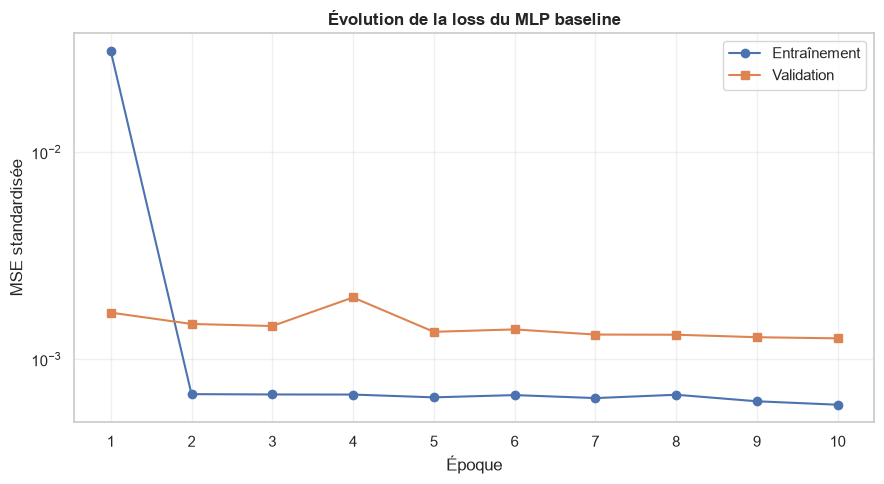

In [24]:
epochs = range(1, EPOCHS + 1)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Entraînement",
)

ax.plot(
    epochs,
    history["validation_loss"],
    marker="s",
    label="Validation",
)

ax.set(
    title="Évolution de la loss du MLP baseline",
    xlabel="Époque",
    ylabel="MSE standardisée",
)

ax.set_yscale("log")
ax.set_xticks(list(epochs))
ax.legend()
ax.grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "01_baseline_loss_curves.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

In [25]:
def predict_scaled(model, loader):
    model.eval()
    predictions = []

    with torch.no_grad():
        for X_batch, _ in loader:
            X_batch = X_batch.to(
                DEVICE,
                non_blocking=use_pin_memory,
            )

            batch_predictions = model(X_batch)
            predictions.append(
                batch_predictions.cpu().numpy()
            )

    return np.vstack(predictions)


test_predictions_scaled = predict_scaled(
    model,
    test_loader,
)

test_predictions = target_scaler.inverse_transform(
    test_predictions_scaled
).ravel()

test_actual = target_scaler.inverse_transform(
    y_test
).ravel()

baseline_predictions = (
    test_data["close"]
    .to_numpy()
)


def calculate_metrics(y_true, y_pred):
    errors = y_true - y_pred

    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors ** 2))

    r2 = 1 - (
        np.sum(errors ** 2)
        / np.sum((y_true - y_true.mean()) ** 2)
    )

    tolerance_accuracy = np.mean(
        np.abs(errors) <= 0.05 * np.abs(y_true)
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Accuracy ±5% (%)": tolerance_accuracy,
    }


comparison = pd.DataFrame({
    "Baseline persistance": calculate_metrics(
        test_actual,
        baseline_predictions,
    ),
    "MLP baseline": calculate_metrics(
        test_actual,
        test_predictions,
    ),
}).T.round(4)

comparison

,MAE,RMSE,R2,Accuracy ±5% (%)
Baseline persistance,0.9484,2.1429,0.9996,97.8109
MLP baseline,0.9811,2.1839,0.9996,97.2235


## 10. Recherche d'hyperparamètres

Je compare 16 configurations (architecture, taux d'apprentissage, optimiseur et nombre d'époques) sur un sous-ensemble déterministe pour limiter le temps de calcul. Je garde le test hors de la sélection, puis je réentraîne la meilleure configuration sur l'ensemble d'entraînement complet.

In [26]:
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from skorch import NeuralNetRegressor


class SearchMLP(nn.Module):
    def __init__(
        self,
        input_dim=5,
        hidden_dims=(64, 32),
    ):
        super().__init__()

        layers = []
        previous_dim = input_dim

        for hidden_dim in hidden_dims:
            layers.extend([
                nn.Linear(previous_dim, hidden_dim),
                nn.ReLU(),
            ])
            previous_dim = hidden_dim

        layers.append(nn.Linear(previous_dim, 1))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


rng = np.random.default_rng(SEED)

grid_train_indices = rng.choice(
    len(X_train),
    size=80_000,
    replace=False,
)

grid_validation_indices = rng.choice(
    len(X_validation),
    size=20_000,
    replace=False,
)

X_grid = np.concatenate([
    X_train[grid_train_indices],
    X_validation[grid_validation_indices],
])

y_grid = np.concatenate([
    y_train[grid_train_indices],
    y_validation[grid_validation_indices],
])

# -1 = entraînement, 0 = validation
test_fold = np.concatenate([
    np.full(len(grid_train_indices), -1),
    np.zeros(len(grid_validation_indices)),
])

predefined_split = PredefinedSplit(test_fold)

In [27]:
search_estimator = NeuralNetRegressor(
    module=SearchMLP,
    module__input_dim=len(FEATURE_COLUMNS),
    criterion=nn.MSELoss,
    optimizer=torch.optim.Adam,
    lr=1e-3,
    max_epochs=5,
    batch_size=4096,
    iterator_train__shuffle=True,
    train_split=None,
    verbose=0,
    device=DEVICE.type,
)

parameter_grid = {
    "module__hidden_dims": [
        (32, 16),
        (64, 32),
    ],
    "lr": [
        5e-4,
        1e-3,
    ],
    "optimizer": [
        torch.optim.Adam,
        torch.optim.RMSprop,
    ],
    "max_epochs": [
        5,
        10,
    ],
}

grid_search = GridSearchCV(
    estimator=search_estimator,
    param_grid=parameter_grid,
    scoring="neg_mean_squared_error",
    cv=predefined_split,
    refit=False,
    n_jobs=1,
    verbose=2,
    error_score="raise",
)

In [28]:
grid_search.fit(X_grid, y_grid)

Fitting 1 folds for each of 16 candidates, totalling 16 fits


[CV] END lr=0.0005, max_epochs=5, module__hidden_dims=(32, 16), optimizer=<class 'torch.optim.adam.Adam'>; total time=   5.4s


[CV] END lr=0.0005, max_epochs=5, module__hidden_dims=(32, 16), optimizer=<class 'torch.optim.rmsprop.RMSprop'>; total time=   5.5s


[CV] END lr=0.0005, max_epochs=5, module__hidden_dims=(64, 32), optimizer=<class 'torch.optim.adam.Adam'>; total time=   5.9s


[CV] END lr=0.0005, max_epochs=5, module__hidden_dims=(64, 32), optimizer=<class 'torch.optim.rmsprop.RMSprop'>; total time=   5.3s


[CV] END lr=0.0005, max_epochs=10, module__hidden_dims=(32, 16), optimizer=<class 'torch.optim.adam.Adam'>; total time=  10.5s


[CV] END lr=0.0005, max_epochs=10, module__hidden_dims=(32, 16), optimizer=<class 'torch.optim.rmsprop.RMSprop'>; total time=  10.3s


[CV] END lr=0.0005, max_epochs=10, module__hidden_dims=(64, 32), optimizer=<class 'torch.optim.adam.Adam'>; total time=  10.2s


[CV] END lr=0.0005, max_epochs=10, module__hidden_dims=(64, 32), optimizer=<class 'torch.optim.rmsprop.RMSprop'>; total time=  10.4s


[CV] END lr=0.001, max_epochs=5, module__hidden_dims=(32, 16), optimizer=<class 'torch.optim.adam.Adam'>; total time=   5.3s


[CV] END lr=0.001, max_epochs=5, module__hidden_dims=(32, 16), optimizer=<class 'torch.optim.rmsprop.RMSprop'>; total time=   5.5s


[CV] END lr=0.001, max_epochs=5, module__hidden_dims=(64, 32), optimizer=<class 'torch.optim.adam.Adam'>; total time=   5.4s


[CV] END lr=0.001, max_epochs=5, module__hidden_dims=(64, 32), optimizer=<class 'torch.optim.rmsprop.RMSprop'>; total time=   5.3s


[CV] END lr=0.001, max_epochs=10, module__hidden_dims=(32, 16), optimizer=<class 'torch.optim.adam.Adam'>; total time=  10.5s


[CV] END lr=0.001, max_epochs=10, module__hidden_dims=(32, 16), optimizer=<class 'torch.optim.rmsprop.RMSprop'>; total time=  10.2s


[CV] END lr=0.001, max_epochs=10, module__hidden_dims=(64, 32), optimizer=<class 'torch.optim.adam.Adam'>; total time=  10.8s


[CV] END lr=0.001, max_epochs=10, module__hidden_dims=(64, 32), optimizer=<class 'torch.optim.rmsprop.RMSprop'>; total time=  10.3s


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","<class 'skorc...input_dim=5, )"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'lr': [0.0005, 0.001], 'max_epochs': [5, 10], 'module__hidden_dims': [(32, ...), (64, ...)], 'optimizer': [<class 'torch...im.adam.Adam'>, <class 'torch...prop.RMSprop'>]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",False
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 

In [29]:
grid_results = pd.DataFrame(
    grid_search.cv_results_
)

grid_results["validation_mse"] = (
    -grid_results["mean_test_score"]
)

grid_results["optimizer_name"] = (
    grid_results["param_optimizer"]
    .apply(lambda optimizer: optimizer.__name__)
)

result_columns = [
    "param_module__hidden_dims",
    "param_lr",
    "optimizer_name",
    "param_max_epochs",
    "validation_mse",
    "mean_fit_time",
]

display(
    grid_results[result_columns]
    .sort_values("validation_mse")
    .reset_index(drop=True)
    .round({
        "param_lr": 5,
        "validation_mse": 6,
        "mean_fit_time": 2,
    })
)

print("Meilleurs hyperparamètres :")
print(grid_search.best_params_)

print(
    "Meilleure MSE de validation :",
    round(-grid_search.best_score_, 6),
)

,param_module__hidden_dims,param_lr,optimizer_name,param_max_epochs,validation_mse,mean_fit_time
0,"(32, 16)",0.0010,RMSprop,10,0.001160,10.02
1,"(64, 32)",0.0010,Adam,10,0.001197,10.59
2,"(64, 32)",0.0005,Adam,10,0.001219,10.06
3,"(64, 32)",0.0005,RMSprop,10,0.001242,10.24
4,"(64, 32)",0.0010,RMSprop,5,0.001269,5.13
5,"(64, 32)",0.0010,Adam,5,0.001291,5.11
6,"(64, 32)",0.0010,RMSprop,10,0.001318,10.04
7,"(32, 16)",0.0010,RMSprop,5,0.001538,5.31
8,"(64, 32)",0.0005,RMSprop,5,0.001575,5.10
9,"(32, 16)",0.0005,Adam,10,0.001617,10.30


Meilleurs hyperparamètres :
{'lr': 0.001, 'max_epochs': 10, 'module__hidden_dims': (32, 16), 'optimizer': <class 'torch.optim.rmsprop.RMSprop'>}
Meilleure MSE de validation : 0.00116


In [30]:
FINAL_BATCH_SIZE = 4096

final_train_loader = DataLoader(
    train_dataset,
    batch_size=FINAL_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=use_pin_memory,
    generator=torch.Generator().manual_seed(SEED),
)

final_validation_loader = DataLoader(
    validation_dataset,
    batch_size=FINAL_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=use_pin_memory,
)

final_test_loader = DataLoader(
    test_dataset,
    batch_size=FINAL_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=use_pin_memory,
)

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

tuned_model = SearchMLP(
    input_dim=len(FEATURE_COLUMNS),
    hidden_dims=(32, 16),
).to(DEVICE)

tuned_optimizer = torch.optim.RMSprop(
    tuned_model.parameters(),
    lr=1e-3,
)

tuned_history = {
    "train_loss": [],
    "validation_loss": [],
}

best_tuned_validation_loss = float("inf")
best_tuned_epoch = None
best_tuned_path = MODELS_DIR / "tuned_mlp.pt"

for epoch in range(1, 11):
    train_loss = train_one_epoch(
        tuned_model,
        final_train_loader,
        criterion,
        tuned_optimizer,
    )

    validation_loss = evaluate_loss(
        tuned_model,
        final_validation_loader,
        criterion,
    )

    tuned_history["train_loss"].append(train_loss)
    tuned_history["validation_loss"].append(
        validation_loss
    )

    if validation_loss < best_tuned_validation_loss:
        best_tuned_validation_loss = validation_loss
        best_tuned_epoch = epoch
        torch.save(
            tuned_model.state_dict(),
            best_tuned_path,
        )

    print(
        f"Epoch {epoch:02d}/10 | "
        f"train_loss={train_loss:.6f} | "
        f"validation_loss={validation_loss:.6f}"
    )

tuned_model.load_state_dict(
    torch.load(
        best_tuned_path,
        map_location=DEVICE,
        weights_only=True,
    )
)

print("Meilleure époque :", best_tuned_epoch)
print(
    "Meilleure validation loss :",
    round(best_tuned_validation_loss, 6),
)

Epoch 01/10 | train_loss=0.026021 | validation_loss=0.001669


Epoch 02/10 | train_loss=0.000820 | validation_loss=0.001491


Epoch 03/10 | train_loss=0.000838 | validation_loss=0.001505


Epoch 04/10 | train_loss=0.000985 | validation_loss=0.002072


Epoch 05/10 | train_loss=0.000910 | validation_loss=0.002138


Epoch 06/10 | train_loss=0.000922 | validation_loss=0.001422


Epoch 07/10 | train_loss=0.000830 | validation_loss=0.001502


Epoch 08/10 | train_loss=0.000896 | validation_loss=0.001412


Epoch 09/10 | train_loss=0.000819 | validation_loss=0.002005


Epoch 10/10 | train_loss=0.000886 | validation_loss=0.001464
Meilleure époque : 8
Meilleure validation loss : 0.001412


In [31]:
tuned_predictions_scaled = predict_scaled(
    tuned_model,
    final_test_loader,
)

tuned_predictions = target_scaler.inverse_transform(
    tuned_predictions_scaled
).ravel()

model_comparison = pd.DataFrame({
    "Persistance": calculate_metrics(
        test_actual,
        baseline_predictions,
    ),
    "MLP initial": calculate_metrics(
        test_actual,
        test_predictions,
    ),
    "MLP GridSearch": calculate_metrics(
        test_actual,
        tuned_predictions,
    ),
}).T.round(4)

model_comparison

,MAE,RMSE,R2,Accuracy ±5% (%)
Persistance,0.9484,2.1429,0.9996,97.8109
MLP initial,0.9811,2.1839,0.9996,97.2235
MLP GridSearch,1.0479,2.2899,0.9995,96.6042


## 11. Régularisation

Je compare trois variantes : pénalisation L2, dropout, puis dropout + L2 + early stopping. Je juge leur intérêt sur le test après sélection par validation.

In [32]:
class RegularizedMLP(nn.Module):
    def __init__(
        self,
        input_dim=5,
        dropout_rate=0.0,
    ):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            nn.Linear(32, 1),
        )

    def forward(self, x):
        return self.network(x)


def run_regularization_experiment(
    experiment_name,
    dropout_rate,
    weight_decay,
    patience=None,
    max_epochs=10,
):
    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    experiment_loader = DataLoader(
        train_dataset,
        batch_size=FINAL_BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        pin_memory=use_pin_memory,
        generator=torch.Generator().manual_seed(SEED),
    )

    experiment_model = RegularizedMLP(
        input_dim=len(FEATURE_COLUMNS),
        dropout_rate=dropout_rate,
    ).to(DEVICE)

    experiment_optimizer = torch.optim.Adam(
        experiment_model.parameters(),
        lr=1e-3,
        weight_decay=weight_decay,
    )

    experiment_history = {
        "train_loss": [],
        "validation_loss": [],
    }

    best_loss = float("inf")
    best_epoch = None
    epochs_without_improvement = 0

    model_path = MODELS_DIR / f"{experiment_name}.pt"

    for epoch in range(1, max_epochs + 1):
        train_loss = train_one_epoch(
            experiment_model,
            experiment_loader,
            criterion,
            experiment_optimizer,
        )

        validation_loss = evaluate_loss(
            experiment_model,
            final_validation_loader,
            criterion,
        )

        experiment_history["train_loss"].append(train_loss)
        experiment_history["validation_loss"].append(
            validation_loss
        )

        if validation_loss < best_loss:
            best_loss = validation_loss
            best_epoch = epoch
            epochs_without_improvement = 0
            torch.save(
                experiment_model.state_dict(),
                model_path,
            )
        else:
            epochs_without_improvement += 1

        print(
            f"{experiment_name} | "
            f"epoch {epoch:02d}/{max_epochs} | "
            f"train={train_loss:.6f} | "
            f"validation={validation_loss:.6f}"
        )

        if (
            patience is not None
            and epochs_without_improvement >= patience
        ):
            print("Early stopping.")
            break

    experiment_model.load_state_dict(
        torch.load(
            model_path,
            map_location=DEVICE,
            weights_only=True,
        )
    )

    return {
        "model": experiment_model,
        "history": experiment_history,
        "best_epoch": best_epoch,
        "best_validation_loss": best_loss,
    }

In [33]:
regularization_experiments = {
    "l2": {
        "dropout_rate": 0.0,
        "weight_decay": 1e-4,
        "patience": None,
    },
    "dropout": {
        "dropout_rate": 0.2,
        "weight_decay": 0.0,
        "patience": None,
    },
    "dropout_l2_early_stopping": {
        "dropout_rate": 0.2,
        "weight_decay": 1e-4,
        "patience": 3,
    },
}

regularization_results = {}

for experiment_name, parameters in regularization_experiments.items():
    print("\n---", experiment_name, "---")

    regularization_results[experiment_name] = (
        run_regularization_experiment(
            experiment_name=experiment_name,
            **parameters,
        )
    )


--- l2 ---


l2 | epoch 01/10 | train=0.127732 | validation=0.001735


l2 | epoch 02/10 | train=0.000706 | validation=0.001563


l2 | epoch 03/10 | train=0.000669 | validation=0.001507


l2 | epoch 04/10 | train=0.000649 | validation=0.001468


l2 | epoch 05/10 | train=0.000644 | validation=0.001502


l2 | epoch 06/10 | train=0.000638 | validation=0.001685


l2 | epoch 07/10 | train=0.000635 | validation=0.001548


l2 | epoch 08/10 | train=0.000631 | validation=0.001414


l2 | epoch 09/10 | train=0.000625 | validation=0.001414


l2 | epoch 10/10 | train=0.000624 | validation=0.001405

--- dropout ---


dropout | epoch 01/10 | train=0.153795 | validation=0.004222


dropout | epoch 02/10 | train=0.035170 | validation=0.004295


dropout | epoch 03/10 | train=0.030288 | validation=0.002717


dropout | epoch 04/10 | train=0.028644 | validation=0.004655


dropout | epoch 05/10 | train=0.027411 | validation=0.002505


dropout | epoch 06/10 | train=0.027781 | validation=0.004891


dropout | epoch 07/10 | train=0.027015 | validation=0.002138


dropout | epoch 08/10 | train=0.027032 | validation=0.004490


dropout | epoch 09/10 | train=0.027406 | validation=0.007923


dropout | epoch 10/10 | train=0.026719 | validation=0.002250

--- dropout_l2_early_stopping ---


dropout_l2_early_stopping | epoch 01/10 | train=0.153626 | validation=0.003387


dropout_l2_early_stopping | epoch 02/10 | train=0.034702 | validation=0.004378


dropout_l2_early_stopping | epoch 03/10 | train=0.029962 | validation=0.002636


dropout_l2_early_stopping | epoch 04/10 | train=0.028397 | validation=0.004618


dropout_l2_early_stopping | epoch 05/10 | train=0.027217 | validation=0.002402


dropout_l2_early_stopping | epoch 06/10 | train=0.027639 | validation=0.004801


dropout_l2_early_stopping | epoch 07/10 | train=0.026936 | validation=0.001937


dropout_l2_early_stopping | epoch 08/10 | train=0.027055 | validation=0.004220


dropout_l2_early_stopping | epoch 09/10 | train=0.027502 | validation=0.007570


dropout_l2_early_stopping | epoch 10/10 | train=0.026843 | validation=0.001880


In [34]:
regularization_metrics = {}

for experiment_name, result in regularization_results.items():
    predictions_scaled = predict_scaled(
        result["model"],
        final_test_loader,
    )

    predictions_original = (
        target_scaler
        .inverse_transform(predictions_scaled)
        .ravel()
    )

    regularization_metrics[experiment_name] = (
        calculate_metrics(
            test_actual,
            predictions_original,
        )
    )


complete_comparison = {
    "Persistance": calculate_metrics(
        test_actual,
        baseline_predictions,
    ),
    "MLP initial": calculate_metrics(
        test_actual,
        test_predictions,
    ),
    "MLP GridSearch": calculate_metrics(
        test_actual,
        tuned_predictions,
    ),
    "L2": regularization_metrics["l2"],
    "Dropout": regularization_metrics["dropout"],
    "Dropout + L2 + early stopping":
        regularization_metrics[
            "dropout_l2_early_stopping"
        ],
}

complete_comparison = (
    pd.DataFrame(complete_comparison)
    .T
    .round(4)
)

complete_comparison

,MAE,RMSE,R2,Accuracy ±5% (%)
Persistance,0.9484,2.1429,0.9996,97.8109
MLP initial,0.9811,2.1839,0.9996,97.2235
MLP GridSearch,1.0479,2.2899,0.9995,96.6042
L2,1.0480,2.2937,0.9995,96.9218
Dropout,1.6114,2.8647,0.9992,83.3312
Dropout + L2 + early stopping,1.3192,2.6681,0.9993,92.5197


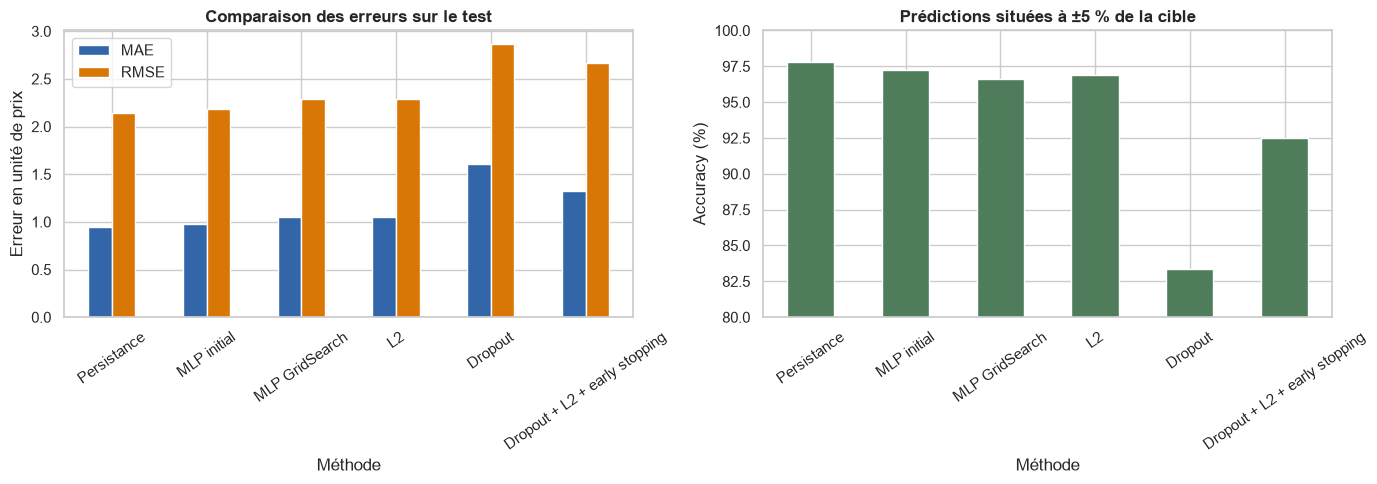

In [35]:
METRICS_DIR = PROJECT_ROOT / "outputs" / "metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

complete_comparison.to_csv(
    METRICS_DIR / "regression_model_comparison.csv"
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
)

complete_comparison[
    ["MAE", "RMSE"]
].plot.bar(
    ax=axes[0],
    color=["#3366A8", "#D97706"],
)

axes[0].set(
    title="Comparaison des erreurs sur le test",
    xlabel="Méthode",
    ylabel="Erreur en unité de prix",
)
axes[0].tick_params(axis="x", rotation=35)
axes[0].legend()


complete_comparison[
    "Accuracy ±5% (%)"
].plot.bar(
    ax=axes[1],
    color="#4F7D5C",
)

axes[1].set(
    title="Prédictions situées à ±5 % de la cible",
    xlabel="Méthode",
    ylabel="Accuracy (%)",
)
axes[1].tick_params(axis="x", rotation=35)
axes[1].set_ylim(80, 100)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "01_model_comparison.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

## 12. Courbes Loss/Epochs et Accuracy/Epochs

Pour cette régression, je définis l'accuracy comme le pourcentage de prédictions dont l'erreur absolue ne dépasse pas 5 % de la cible. J'utilise les métriques de test par époque uniquement pour produire les courbes demandées par l'énoncé, pas pour choisir le modèle.

In [36]:
def evaluate_loss_and_accuracy(model, loader):
    model.eval()

    total_squared_error = 0.0
    total_correct = 0
    total_examples = 0

    target_mean = float(target_scaler.mean_[0])
    target_scale = float(target_scaler.scale_[0])

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(
                DEVICE,
                non_blocking=use_pin_memory,
            )
            y_batch = y_batch.to(
                DEVICE,
                non_blocking=use_pin_memory,
            )

            predictions = model(X_batch)

            total_squared_error += (
                (predictions - y_batch) ** 2
            ).sum().item()

            predictions_original = (
                predictions * target_scale
                + target_mean
            )

            targets_original = (
                y_batch * target_scale
                + target_mean
            )

            correct = (
                torch.abs(
                    predictions_original
                    - targets_original
                )
                <= 0.05 * torch.abs(targets_original)
            )

            total_correct += correct.sum().item()
            total_examples += y_batch.numel()

    return {
        "loss": total_squared_error / total_examples,
        "accuracy": 100 * total_correct / total_examples,
    }


torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

reporting_model = RegularizedMLP(
    input_dim=len(FEATURE_COLUMNS),
    dropout_rate=0.0,
).to(DEVICE)

reporting_optimizer = torch.optim.Adam(
    reporting_model.parameters(),
    lr=1e-3,
)

epoch_snapshots = []

for epoch in range(1, 11):
    train_one_epoch(
        reporting_model,
        final_train_loader,
        criterion,
        reporting_optimizer,
    )

    epoch_snapshots.append({
        name: tensor.detach().cpu().clone()
        for name, tensor
        in reporting_model.state_dict().items()
    })

    print(f"Époque {epoch}/10 enregistrée")

Époque 1/10 enregistrée


Époque 2/10 enregistrée


Époque 3/10 enregistrée


Époque 4/10 enregistrée


Époque 5/10 enregistrée


Époque 6/10 enregistrée


Époque 7/10 enregistrée


Époque 8/10 enregistrée


Époque 9/10 enregistrée


Époque 10/10 enregistrée


In [37]:
epoch_metrics = []

for epoch, state_dict in enumerate(
    epoch_snapshots,
    start=1,
):
    reporting_model.load_state_dict(state_dict)

    train_metrics = evaluate_loss_and_accuracy(
        reporting_model,
        final_train_loader,
    )

    test_metrics = evaluate_loss_and_accuracy(
        reporting_model,
        final_test_loader,
    )

    epoch_metrics.append({
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "test_loss": test_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "test_accuracy": test_metrics["accuracy"],
    })

    print(
        f"Époque {epoch:02d} | "
        f"train_acc={train_metrics['accuracy']:.2f}% | "
        f"test_acc={test_metrics['accuracy']:.2f}%"
    )

epoch_metrics = pd.DataFrame(epoch_metrics)
epoch_metrics.to_csv(
    METRICS_DIR / "regression_epoch_metrics.csv",
    index=False,
)

epoch_metrics.round(6)

Époque 01 | train_acc=90.42% | test_acc=92.52%


Époque 02 | train_acc=95.36% | test_acc=95.44%


Époque 03 | train_acc=96.45% | test_acc=96.25%


Époque 04 | train_acc=97.03% | test_acc=96.64%


Époque 05 | train_acc=94.65% | test_acc=95.44%


Époque 06 | train_acc=97.38% | test_acc=96.91%


Époque 07 | train_acc=96.98% | test_acc=96.77%


Époque 08 | train_acc=94.99% | test_acc=95.66%


Époque 09 | train_acc=97.27% | test_acc=96.92%


Époque 10 | train_acc=97.03% | test_acc=96.82%


,epoch,train_loss,test_loss,train_accuracy,test_accuracy
0,1,0.000780,0.001736,90.415914,92.515761
1,2,0.000675,0.001570,95.358284,95.435586
2,3,0.000661,0.001551,96.454513,96.245144
3,4,0.000642,0.001494,97.029975,96.640769
4,5,0.000657,0.001506,94.650754,95.436382
5,6,0.000626,0.001462,97.376820,96.908234
6,7,0.000620,0.001440,96.984786,96.769726
7,8,0.000633,0.001438,94.993597,95.658473
8,9,0.000618,0.001453,97.273600,96.921767
9,10,0.000608,0.001422,97.031810,96.819079


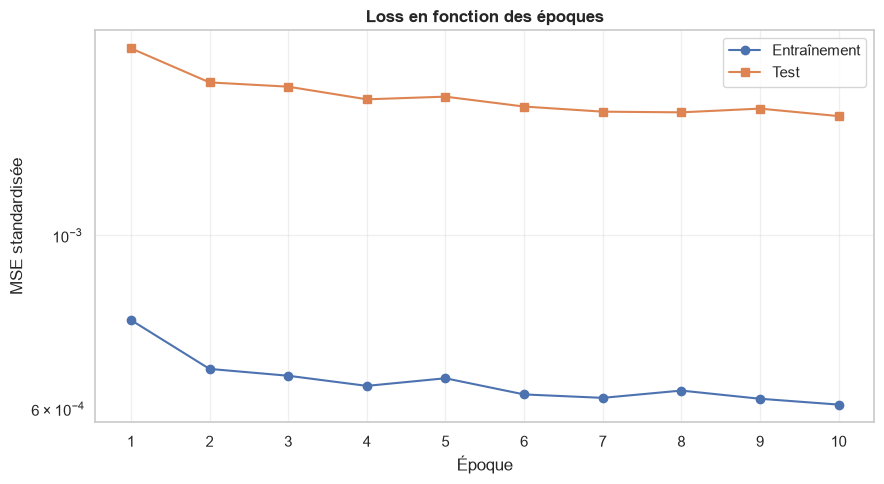

In [38]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    epoch_metrics["epoch"],
    epoch_metrics["train_loss"],
    marker="o",
    label="Entraînement",
)

ax.plot(
    epoch_metrics["epoch"],
    epoch_metrics["test_loss"],
    marker="s",
    label="Test",
)

ax.set(
    title="Loss en fonction des époques",
    xlabel="Époque",
    ylabel="MSE standardisée",
)

ax.set_yscale("log")
ax.set_xticks(epoch_metrics["epoch"])
ax.legend()
ax.grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "01_loss_train_test.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

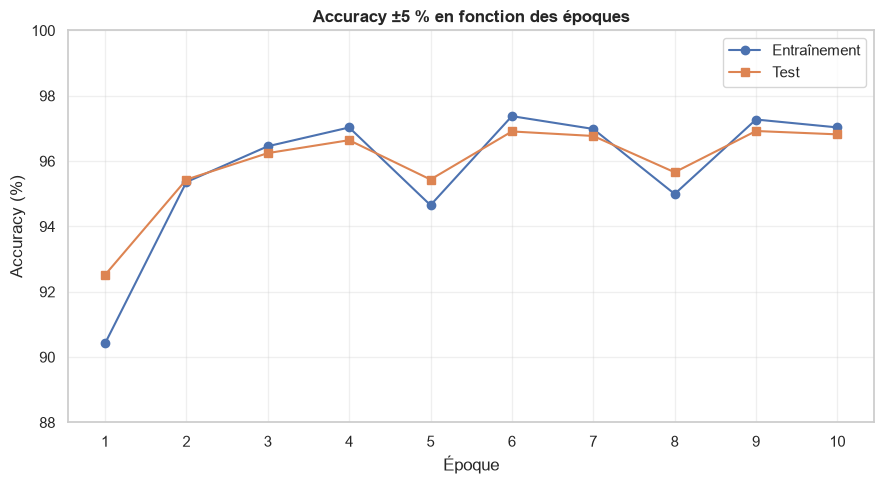

In [39]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    epoch_metrics["epoch"],
    epoch_metrics["train_accuracy"],
    marker="o",
    label="Entraînement",
)

ax.plot(
    epoch_metrics["epoch"],
    epoch_metrics["test_accuracy"],
    marker="s",
    label="Test",
)

ax.set(
    title="Accuracy ±5 % en fonction des époques",
    xlabel="Époque",
    ylabel="Accuracy (%)",
)

ax.set_xticks(epoch_metrics["epoch"])
ax.set_ylim(88, 100)
ax.legend()
ax.grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "01_accuracy_train_test.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

In [40]:
grid_results[result_columns].to_csv(
    METRICS_DIR / "grid_search_results.csv",
    index=False,
)

print("Résultats GridSearch sauvegardés.")

Résultats GridSearch sauvegardés.


## 13. Synthèse

- J'obtiens la meilleure MAE sur le test avec la **persistance** (`prédiction = clôture du jour`) : **0,9484**, contre **0,9811** pour mon MLP initial.
- Mon MLP initial est le meilleur réseau testé, mais il ne surpasse pas cette règle simple. J'interprète prudemment la forte valeur de R², car deux prix consécutifs sont très corrélés.
- Ma recherche sur sous-échantillon n'améliore pas le résultat final. L2 dégrade légèrement les erreurs et le dropout sous-apprend nettement.
- Mes courbes train/test restent proches et ne montrent pas de divergence progressive : je ne détecte pas de signe fort d'overfitting sur dix époques.
- Mon principal enseignement méthodologique est qu'un réseau doit battre une baseline pertinente pour justifier sa complexité.

Les tableaux détaillés sont sauvegardés dans `outputs/metrics/` et les figures dans `outputs/figures/`.